*Mathematical Foundations of Robotics · Chapter 1 — Introduction, Joints and Degrees of Freedom*

# 1.3 Degrees of Freedom and Grübler's Formula

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/01-introduction-and-degrees-of-freedom/1.3-degrees-of-freedom-and-grublers-formula.ipynb)

How many numbers must be specified to fix the configuration of a mechanism? That number, its **degrees of freedom**
(DOF), decides how many actuators it needs and what its inverse-kinematics problem looks like. For a serial arm the
answer is simply the number of joints; for a mechanism with closed loops it is smaller, and **Grübler's formula**
counts it. This notebook derives the formula from the freedom of a rigid body, applies it to the four-bar, the
slider-crank, the Stewart platform and serial arms, *checks every count numerically* — by the rank of the loop-closure
constraints and by the MuJoCo simulator — and then shows, with working examples, the paradoxical mechanisms for which
the formula fails.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., Ch. 1 (the degrees of freedom of a manipulator) and §3.1 |
| **Parallel reading** | Lynch & Park, *Modern Robotics*, §2.1–2.2 (degrees of freedom of a rigid body and of a robot; Grübler's formula) · Spong et al., Ch. 1 · Siciliano et al., Ch. 1–2 |
| **Lectures** | [Modern Robotics — 2.1 DOF of a rigid body](https://www.youtube.com/watch?v=z29hYlagOYM) · [Modern Robotics — 2.2 DOF of a robot (Grübler)](https://www.youtube.com/watch?v=zI64DyaRUvQ) · [Prof. G. C. Nandi — Lecture 2 — A simple two-link manipulator](https://www.youtube.com/watch?v=4eAlCjFMq2Q) |
| **Prerequisites** | [1.1 Robots, Links and Joints](1.1-robots-links-and-joints.ipynb); [1.2 A Tour of Real Robots](1.2-a-tour-of-real-robots.ipynb) is helpful |
| **Study time** | about 3 hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. define the degrees of freedom of a system and derive that a rigid body has 3 DOF in the plane and 6 in space by counting points;
2. derive Grübler's formula $m(N-1-J)+\sum f_i$ from the constraints removed by each joint;
3. apply it to serial arms, the four-bar, the slider-crank, the Stewart platform and a humanoid in double support;
4. verify a count independently as $n - \operatorname{rank}(\partial\Phi/\partial q)$ for the loop-closure equations $\Phi(q)=0$, and in MuJoCo;
5. recognise when the formula fails (redundant constraints, passive freedoms, special configurations) and explain why;
6. simulate the four-bar and slider-crank by solving their loop-closure equations numerically.

## Contents

1. [Degrees of freedom of a rigid body](#1.-Degrees-of-freedom-of-a-rigid-body)
2. [Constraints of a joint and Grübler's formula](#2.-Constraints-of-a-joint-and-Grübler's-formula)
3. [Serial arms and the four-bar linkage](#3.-Serial-arms-and-the-four-bar-linkage)
4. [The slider-crank and the Stewart platform](#4.-The-slider-crank-and-the-Stewart-platform)
5. [Counting with the simulator](#5.-Counting-with-the-simulator)
6. [When Grübler's formula fails](#6.-When-Grübler's-formula-fails)
7. [Worked examples](#7.-Worked-examples)
8. [Summary, common mistakes and exercises](#8.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import mujoco_utils as mju, robots, joint_census as jc, mechanisms as mech
import mujoco

## 1. Degrees of freedom of a rigid body

The **degrees of freedom** of a system are the smallest number of independent real coordinates that fix its
configuration completely. A bead on a wire has one; a point in the plane has two; a point in space has three. For a
**rigid body** the answer can be found by *counting points and subtracting constraints*.

Take three non-collinear points $A$, $B$, $C$ of a body in space; they determine the body's position and orientation.
Point $A$ is free: 3 coordinates. Point $B$ must stay at a fixed distance from $A$, so it lies on a sphere about $A$: 2 coordinates.
Point $C$ must keep fixed distances from both $A$ and $B$, so it lies on a circle: 1 coordinate. Hence
$3 + 2 + 1 = 6$. In the plane the same argument gives $2 + 1 = 3$ (the second point lies on a circle about the first, and the
third is then fixed up to a reflection). Equivalently,

$$
\text{DOF} = \sum(\text{freedoms of the points}) - (\text{number of independent constraints}),
\qquad 3\cdot3 - 3 = 6\ \ (\text{space}),\quad 2\cdot 3 - 3 = 3\ \ (\text{plane}). \tag{1.3}
$$

Three distance constraints among three points fix their mutual distances, whatever the number of further points on the body: a
fourth point is fixed by 3 more distances but adds 3 coordinates, so the count stays at 6. The computation below confirms
this with the **rigidity matrix** — one row $(\mathbf p_i - \mathbf p_j)$ per fixed distance, whose rank is the number of independent
constraints (valid for points in general position).

In [2]:
rng = np.random.default_rng(3)
print(" n points | DOF in space (3n - rank) | DOF in the plane (2n - rank)")
for n in range(2, 9):
    print(f"   {n:2d}     |            {mech.rigidity_dof(rng.normal(size=(n, 3))):2d}             |            {mech.rigidity_dof(rng.normal(size=(n, 2))):2d}")
assert all(mech.rigidity_dof(rng.normal(size=(n, 3))) == 6 for n in range(3, 9)) and all(mech.rigidity_dof(rng.normal(size=(n, 2))) == 3 for n in range(3, 9))

 n points | DOF in space (3n - rank) | DOF in the plane (2n - rank)
    2     |             5             |             3
    3     |             6             |             3
    4     |             6             |             3
    5     |             6             |             3
    6     |             6             |             3
    7     |             6             |             3
    8     |             6             |             3


The count saturates at 6 (space) and 3 (plane) as soon as there are three points: adding points to a body adds no freedom.
(Two points in space, a thin rod, give 5: rotation about the rod's own axis is not a freedom of a *line*.)

> **Result.** A rigid body has $m = 6$ DOF in space and $m = 3$ DOF in the plane. In space, three are translations and three are
> rotations; in the plane, two translations and one rotation.

## 2. Constraints of a joint and Grübler's formula

Consider a mechanism of $N$ links **including the ground (link 0)**, joined by $J$ joints. Before any joint is added, the $N-1$
moving links are free bodies, so the mechanism has $m(N-1)$ freedoms. A joint $i$ that allows $f_i$ relative freedoms between its
two links **removes** $c_i = m - f_i$ of them (Notebook 1.1: $c = 6 - f$ in space, $c = 3 - f$ in the plane). Provided these constraints
are *independent*,

$$
\boxed{\ \text{DOF} = m(N-1) - \sum_{i=1}^{J}(m - f_i) = m\,(N - 1 - J) + \sum_{i=1}^{J} f_i\ } \tag{1.4}
$$

This is the **Grübler–Kutzbach formula** ($m=3$ planar, $m=6$ spatial). The three ideas to hold on to are:

* Every **link** adds $m$ freedoms, every **joint** removes $m - f_i$.
* The ground does not move, so it is excluded from the $N-1$ moving bodies *but included in $N$*.
* Only $J$ and the $f_i$ matter, not the shape: the formula ignores link lengths and joint axes. That is its strength and its weakness
  (Section 6).

For a **serial chain** of $n$ one-freedom joints, $N = n+1$ and $J = n$, so $\text{DOF} = m\cdot 0 + n = n$: the number of joints.
Closed loops make $J$ larger than $N-1$, so the first term becomes *negative*: each independent loop subtracts $m$ from the freedom
(recall $L = J - N + 1$ from Notebook 1.1), giving the alternative form $\text{DOF} = \sum f_i - mL$.

A robust companion to (1.4) does not count at all. If the configuration is described by $n$ coordinates $q$ subject to loop-closure
equations $\Phi(q) = 0$, then near a regular configuration the set of solutions has dimension

$$
\text{DOF} = n - \operatorname{rank}\,\frac{\partial \Phi}{\partial q}. \tag{1.5}
$$

Equation (1.5) is exact (it counts the *independent* constraints, which (1.4) merely assumes), and `PlanarLinkage.mobility` evaluates it. The rest of the notebook applies (1.4) and (1.5) side by side.

## 3. Serial arms and the four-bar linkage

**Serial arms.** An $n$R arm in space has $N=n+1$, $J=n$, $f_i = 1$: $6(n+1-1-n)+n = n$. A UR5e therefore has 6 DOF — exactly enough to place and orient
a tool (6 numbers) — whereas a Panda has 7, one more than needed. Notebook 1.5 returns to this redundancy.

**The planar four-bar linkage** has ground, crank, coupler and rocker ($N=4$) joined by four revolute joints ($J=4$, $f_i=1$):

$$\text{DOF} = 3(4 - 1 - 4) + 4\cdot 1 = -3 + 4 = 1.$$

One angle — that of the crank, driven by a single motor — fixes the whole linkage. The code builds the four-bar as a `PlanarLinkage`
(each body has coordinates $(x, y, \theta)$, each revolute joint gives two equations), counts by (1.4) and by (1.5), and then
**moves** it by solving the loop-closure equations with Newton's method from the previous configuration (*continuation*).
The coupler point (a point fixed on the coupler away from its line of joints) traces a *coupler curve*.

Grübler (planar): 1 | coordinates n = 9 | equations = 8 | numerical mobility n - rank = 1 | residual of the assembled configuration: 4.440892098500626e-16
Grashof classification: Grashof, crank-rocker (crank is the shortest link)
Newton continuation reproduces the closed-form rocker angle over a full crank turn: True


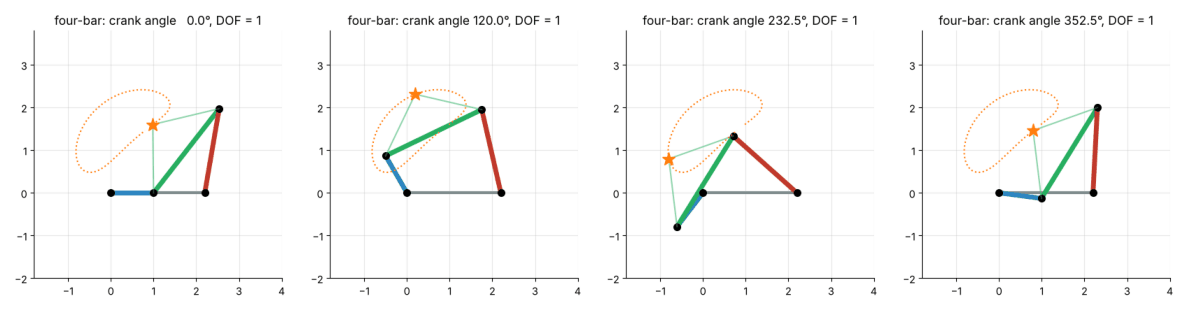

In [3]:
a, b, c, dgr = 1.0, 2.5, 2.0, 2.2                       # crank, coupler, rocker, ground (in units of 10 cm, say)
th0 = 0.7
L4, q0 = mech.fourbar_linkage(a, b, c, dgr, th0)
print("Grübler (planar):", L4.grubler(), "| coordinates n =", L4.n_coords, "| equations =", len(L4.residual(q0)),
      "| numerical mobility n - rank =", L4.mobility(q0)[0], "| residual of the assembled configuration:", np.abs(L4.residual(q0)).max())
assert L4.grubler() == 1 == L4.mobility(q0)[0]
print("Grashof classification:", mech.grashof_type(a, b, c, dgr))

# motion by Newton continuation on the crank angle (coordinate index 2 is theta_1 = crank angle)
thetas = np.linspace(0, 2 * np.pi, 49)[:-1]
qs, q = [], q0.copy()
for th in thetas:
    q = L4.solve(q, fixed={2: th}); qs.append(q.copy())
qs = np.array(qs)
# compare with the closed form
th4_closed = np.array([mech.fourbar_closure(a, b, c, dgr, th, +1)[1] for th in thetas])
branch_ok = np.allclose(np.unwrap(qs[:, 8]), np.unwrap(th4_closed), atol=1e-8) or np.allclose(qs[:, 8], th4_closed, atol=1e-8)
print("Newton continuation reproduces the closed-form rocker angle over a full crank turn:", branch_ok)

def coupler_point(q):                                      # a point on the coupler, 1.0 off the line AB
    A = q[3:5]; th3 = q[5]
    return A + _rot(th3) @ np.array([b / 2, 1.0])
_rot = lambda t: np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
curve = np.array([coupler_point(q) for q in qs])

fig, ax = plt.subplots(figsize=(6.0, 4.6))
def update(i):
    ax.cla(); q = qs[i]
    O2, A, B, O4 = np.zeros(2), q[3:5], L4.point(q, 2, (b, 0)), np.array([dgr, 0.0])
    ax.plot(*zip(O2, O4), "-", color="#7f8c8d", lw=3); ax.plot(*zip(O2, A), "-", color="#2e86c1", lw=5)
    ax.plot(*zip(A, B), "-", color="#27ae60", lw=5); ax.plot(*zip(O4, B), "-", color="#c0392b", lw=5)
    ax.plot(*zip(*[O2, A, B, O4]), "o", color="k", ms=7)
    P = coupler_point(q); ax.plot(*zip(A, P, B), "-", color="#27ae60", lw=1.5, alpha=0.5)
    ax.plot(*curve.T, ":", color="#ff7f0e", lw=1.5); ax.plot(*P, "*", color="#ff7f0e", ms=14)
    ax.set_xlim(-1.8, 4.0); ax.set_ylim(-2.0, 3.8); ax.set_aspect("equal"); ax.set_title(rf"four-bar: crank angle {np.degrees(thetas[i]):5.1f}°, DOF = 1")
animate(fig, update, range(len(thetas)), interval=70, gif="assets/1.3-fourbar-loop-closure.gif", n_keyframes=4)

A single motor drives the whole mechanism around its loop, and the coupler point (the star) traces a closed curve — the basis of
many linkage designs. Which assembly is reached depends on the *branch* of the loop-closure solution: there are two mirror-image
ways to put a four-bar together for each crank angle, and Newton's method stays on the branch it started on.

## 4. The slider-crank and the Stewart platform

**Slider-crank.** The mechanism of a piston engine has ground, crank, connecting rod and piston ($N=4$) with three revolute joints and one
prismatic joint ($J=4$): $3(4-1-4)+4 = 1$. Solving its loop closure gives the piston position
$x = r\cos\theta + \sqrt{l^2 - r^2\sin^2\theta}$ for crank radius $r$ and rod length $l$ (no offset). We compare this closed form with the
Newton solution of the generic planar solver, which has no knowledge of the formula.

**Stewart platform.** A platform is connected to the ground by six extensible legs. Each leg is a universal joint ($f=2$) at the base, a
prismatic joint ($f=1$) and a spherical joint ($f=3$) at the platform. With $N = 2 + 6\cdot 2 = 14$ links and $J = 18$:

$$\text{DOF} = 6(14 - 1 - 18) + 6\cdot 2 + 6\cdot 1 + 6\cdot 3 = -30 + 36 = 6.$$

The six leg lengths fix the platform's six DOF, which is why it is used as a flight-simulator motion base. We verify (1.5): the
variables are the platform pose (6) and the six leg lengths, the equations are the six distance relations
$\lVert \text{tip}_i - \text{base}_i\rVert^2 = \ell_i^2$. Locking $k$ leg lengths adds $k$ equations and must reduce the DOF to $6-k$.

slider-crank: Grübler = 1 | numerical mobility = 1
max |Newton - formula| for the piston position: 4.2943426592501055e-13


Stewart platform: Grübler = 6 | numerical DOF with 0..6 legs locked: [6, 5, 4, 3, 2, 1, 0]


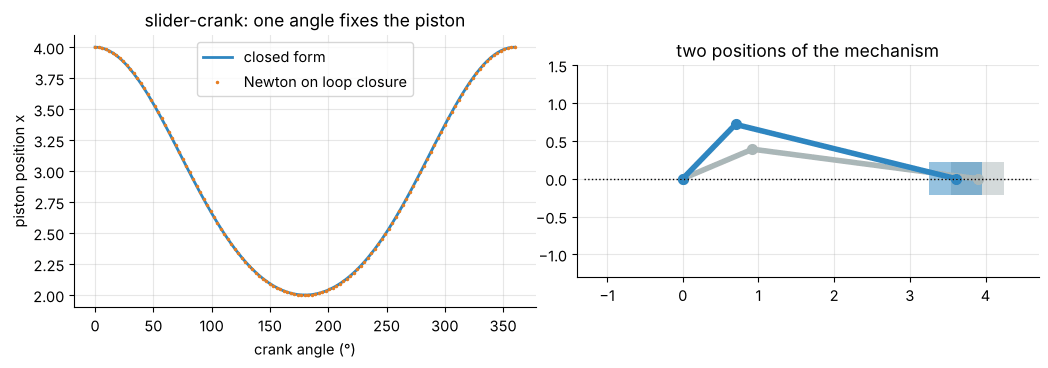

In [4]:
r, l = 1.0, 3.0
Lsc, qsc = mech.slider_crank_linkage(r, l, 0.8)
print("slider-crank: Grübler =", Lsc.grubler(), "| numerical mobility =", Lsc.mobility(qsc)[0])
th = np.linspace(0, 2 * np.pi, 121)
xs_num, q = [], qsc.copy()
for t in th:
    q = Lsc.solve(q, fixed={2: t}); xs_num.append(q[6])           # coordinate 6 = x of the piston
xs_num = np.array(xs_num); xs_formula = r * np.cos(th) + np.sqrt(l ** 2 - r ** 2 * np.sin(th) ** 2)
print("max |Newton - formula| for the piston position:", np.abs(xs_num - xs_formula).max())
assert np.abs(xs_num - xs_formula).max() < 1e-9 and Lsc.grubler() == 1 == Lsc.mobility(qsc)[0]

base, plat = mech.stewart_geometry()
pos, rv = np.array([0.0, 0.0, 1.0]), np.array([0.1, 0.05, 0.2])
dofs = [mech.stewart_mobility(base, plat, pos, rv, locked_legs=range(k)) for k in range(7)]
print("Stewart platform: Grübler =", mech.grubler_spatial(14, [2] * 6 + [1] * 6 + [3] * 6), "| numerical DOF with 0..6 legs locked:", dofs)
assert dofs == [6, 5, 4, 3, 2, 1, 0]

fig, axs = plt.subplots(1, 2, figsize=(10.6, 3.8))
axs[0].plot(np.degrees(th), xs_formula, "-", color="#2e86c1", lw=2, label="closed form"); axs[0].plot(np.degrees(th), xs_num, ".", ms=3, color="#e67e22", label="Newton on loop closure")
axs[0].set_xlabel("crank angle (°)"); axs[0].set_ylabel("piston position x"); axs[0].legend(); axs[0].set_title("slider-crank: one angle fixes the piston")
ax = axs[1]
for t_, col in [(0.4, "#aab7b8"), (0.8, "#2e86c1")]:
    Lq, qq = mech.slider_crank_linkage(r, l, t_); P = mech.slider_crank_points(r, l, t_)
    ax.plot(*P.T, "-o", color=col, lw=4, ms=7)
    ax.add_patch(plt.Rectangle((P[2, 0] - 0.35, -0.22), 0.7, 0.44, fc=col, alpha=0.5))
ax.plot([-1.3, 4.6], [0, 0], "k:", lw=1); ax.set_xlim(-1.4, 4.7); ax.set_ylim(-1.3, 1.5); ax.set_aspect("equal"); ax.set_title("two positions of the mechanism")
plt.tight_layout(); plt.show()

## 5. Counting with the simulator

Formula (1.5) can be applied to *any* model that a simulator builds. MuJoCo describes a mechanism as a tree of joints (`nv` velocity
coordinates) plus **equality constraints** that close the loops; the rank of the constraint Jacobian is available after
`mj_forward`, and `joint_census.model_mobility` returns $n_v - \operatorname{rank}$. We use it on four examples — a planar
four-bar built from three hinges and a `connect` constraint, a slider-crank, and two **real robots whose end link is welded to the
world**, which turns a serial chain into a closed one.

* A **6R** arm (UR5e) with its tool welded to the world has $N = 7$ links, $J = 7$ joints (the weld has $f=0$): $6(7-1-7) + 6 = 0$ DOF.
  The arm is locked, as it must be: six joints have to satisfy six constraints.
* A **7R** arm (iiwa 14) in the same situation has $6(8-1-8) + 7 = 1$ DOF: one joint can still move while the tool stays put — the
  **self-motion** of a redundant arm (Chapter 5).
* A humanoid (**OP3**) standing with **both feet fixed** has $N = 14$ links (ground, pelvis, and two six-link legs), $J = 12 + 2$ contacts ($f=0$)
  and $6(14-1-14)+12 = 6$ DOF in the lower body; the torso carries arms and head with 8 further joints, giving $14$ in all.

In [5]:
def planar_model(kind, a=1.0, b=2.5, c=2.0, d=2.2, th2=0.7):
    """MuJoCo four-bar (three hinges + a connect constraint closing the loop); returns the model and an assembled state."""
    G = 'contype="0" conaffinity="0"'
    th3, th4 = mech.fourbar_closure(a, b, c, d, th2)
    xml = f"""<mujoco><option jacobian="dense"/><worldbody>
     <body name="crank"><joint name="j2" type="hinge" axis="0 1 0"/><geom type="capsule" fromto="0 0 0 {a} 0 0" size="0.02" {G}/>
      <body name="coupler" pos="{a} 0 0"><joint name="j3" type="hinge" axis="0 1 0"/><geom type="capsule" fromto="0 0 0 {b} 0 0" size="0.02" {G}/><site name="B" pos="{b} 0 0"/></body></body>
     <body name="rocker" pos="{d} 0 0"><joint name="j4" type="hinge" axis="0 1 0"/><geom type="capsule" fromto="0 0 0 {c} 0 0" size="0.02" {G}/><site name="B2" pos="{c} 0 0"/></body>
    </worldbody><equality><connect site1="B" site2="B2"/></equality></mujoco>"""
    m = mujoco.MjModel.from_xml_string(xml); dd = mujoco.MjData(m)
    dd.qpos[:] = [-th2, -(th3 - th2), -th4]                     # MuJoCo hinges about +y turn x towards -z, hence the signs
    mujoco.mj_forward(m, dd); return m, dd

m4, d4 = planar_model("fourbar")
print(f"MuJoCo four-bar: nv = {m4.nv}, loop closed (|efc_pos| = {np.abs(d4.efc_pos[:3]).max():.1e}), rank of the equality Jacobian = {jc.equality_rank(m4, d4)} "
      f"-> mobility {jc.model_mobility(m4, d4)} (Grübler: 1)")
print("   (the connect constraint has 3 equations; for a planar motion the one along the hinge axis is redundant, so the rank is 2)")

I = '<inertial pos="0 0 0" mass="0.1" diaginertia="1e-3 1e-3 1e-3"/>'
G = 'contype="0" conaffinity="0"'
r_, l_, th_ = 1.0, 3.0, 0.8
x_ = mech.slider_crank_x(r_, l_, th_); pin = r_ * np.array([np.cos(th_), np.sin(th_)]); phi = np.arctan2(-pin[1], x_ - pin[0])
xml = f"""<mujoco><option jacobian="dense"/><worldbody>
 <body name="crank"><joint name="j1" type="hinge" axis="0 1 0"/><geom type="capsule" fromto="0 0 0 {r_} 0 0" size="0.02" {G}/>
  <body name="rod" pos="{r_} 0 0"><joint name="j2" type="hinge" axis="0 1 0"/><geom type="capsule" fromto="0 0 0 {l_} 0 0" size="0.02" {G}/><site name="pin" pos="{l_} 0 0"/></body></body>
 <body name="piston" pos="0 0 0">{I}<joint name="s" type="slide" axis="1 0 0"/><geom type="box" size="0.1 0.1 0.1" {G}/><site name="pin2" pos="0 0 0"/></body>
</worldbody><equality><connect site1="pin" site2="pin2"/></equality></mujoco>"""
msc = mujoco.MjModel.from_xml_string(xml); dsc = mujoco.MjData(msc)
dsc.qpos[:] = [-th_, -(phi - th_), x_]; mujoco.mj_forward(msc, dsc)
print(f"MuJoCo slider-crank: nv = {msc.nv}, loop error {np.abs(dsc.efc_pos[:3]).max():.1e}, mobility = {jc.model_mobility(msc, dsc)} (Grübler: 1)")
assert jc.model_mobility(m4, d4) == 1 == jc.model_mobility(msc, dsc)

def welded(name, bodies, q=None):
    """Real robot with the given bodies welded to the world (a serial chain closed through the ground)."""
    folder = robots.fetch(name); spec = robots.ROBOTS[name]
    f = folder / "rg_weld_tmp.xml"
    f.write_text(f'<mujoco><include file="{spec["robot"]}"/><option jacobian="dense"/><equality>'
                 + "".join(f'<weld body1="{b}"/>' for b in bodies) + '</equality></mujoco>')
    m = mujoco.MjModel.from_xml_path(str(f)); d = mujoco.MjData(m)
    d.qpos[:] = m.qpos0 if q is None else q
    mujoco.mj_forward(m, d); return m, d

rng = np.random.default_rng(5)
def random_pose(m):
    q = m.qpos0.copy()
    for j in range(m.njnt):
        if m.jnt_type[j] == 3:
            lo, hi = (m.jnt_range[j] if m.jnt_limited[j] else (-1.0, 1.0)); q[m.jnt_qposadr[j]] = rng.uniform(0.3 * lo, 0.3 * hi)
    return q

mu, du = welded("ur5e", ["wrist_3_link"]); du.qpos[:] = random_pose(mu); mujoco.mj_forward(mu, du)
print(f"UR5e tool welded to the world: nv = {mu.nv}, constraint rank = {jc.equality_rank(mu, du)} -> mobility {jc.model_mobility(mu, du)}   (Grübler: 0)")
mi, di = welded("iiwa14", ["link7"]); di.qpos[:] = random_pose(mi); mujoco.mj_forward(mi, di)
print(f"iiwa 14 tool welded to the world: nv = {mi.nv}, constraint rank = {jc.equality_rank(mi, di)} -> mobility {jc.model_mobility(mi, di)}   (Grübler: 1 = the self-motion)")
mo, do = welded("op3", ["l_ank_roll_link", "r_ank_roll_link"])
q = mo.qpos0.copy()
for nm, v in [("l_hip_pitch", -0.5), ("l_knee", 1.0), ("l_ank_pitch", -0.5), ("r_hip_pitch", -0.5), ("r_knee", 1.0), ("r_ank_pitch", -0.5)]:
    q[mo.jnt_qposadr[mujoco.mj_name2id(mo, mujoco.mjtObj.mjOBJ_JOINT, nm)]] = v
do.qpos[:] = q; mujoco.mj_forward(mo, do)
print(f"OP3 with both feet welded to the world (knees bent): nv = {mo.nv}, constraint rank = {jc.equality_rank(mo, do)} -> mobility {jc.model_mobility(mo, do)}   (Grübler: 6 + 8 = 14)")
assert jc.model_mobility(mu, du) == 0 and jc.model_mobility(mi, di) == 1 and jc.model_mobility(mo, do) == 14

MuJoCo four-bar: nv = 3, loop closed (|efc_pos| = 2.2e-16), rank of the equality Jacobian = 2 -> mobility 1 (Grübler: 1)
   (the connect constraint has 3 equations; for a planar motion the one along the hinge axis is redundant, so the rank is 2)
MuJoCo slider-crank: nv = 3, loop error 1.1e-16, mobility = 1 (Grübler: 1)


UR5e tool welded to the world: nv = 6, constraint rank = 6 -> mobility 0   (Grübler: 0)
iiwa 14 tool welded to the world: nv = 7, constraint rank = 6 -> mobility 1   (Grübler: 1 = the self-motion)


OP3 with both feet welded to the world (knees bent): nv = 26, constraint rank = 12 -> mobility 14   (Grübler: 6 + 8 = 14)


In every case the simulator's rank count, the numerical mobility of (1.5) and the Grübler count agree. Note the **rank of the planar
`connect` constraint is 2, not 3**: a `connect` constraint equates two points in three dimensions (three equations), but a
mechanism that moves in a plane satisfies the out-of-plane equation identically. This is the first example of what Section 6 is
about: *the formula assumes independent constraints; the simulator counts the independent ones*.

## 6. When Grübler's formula fails

Formula (1.4) counts $m(N-1)$ freedoms and subtracts $m - f_i$ for each joint, **assuming** that every joint constraint removes a
different freedom. When the geometry makes some constraints dependent (*redundant*), the formula **underestimates** the DOF: it is
a *lower bound*. Four situations occur in practice.

1. **Using the wrong $m$.** Applying the spatial formula ($m=6$) to the planar four-bar gives $6(4-1-4)+4 = -2$, an absurdity. The
   planar mechanism has 3 constraints per joint, not 5, because motion out of the plane is already prevented by the geometry.
2. **Special geometry (overconstrained mechanisms).** The *coupling-rod linkage* of a steam locomotive — three equal cranks joined by one
   rod so that every loop is a parallelogram — has $N=5$, $J=6$, so (1.4) gives $3(5-1-6)+6 = 0$ (a rigid structure!) although it
   rolls freely with 1 DOF. The **Bennett linkage**, a spatial four-bar with 4 revolute joints and special link parameters, has $6(4-1-4)+4=-2$ but moves with 1 DOF.
3. **Passive freedoms.** A joint may add a freedom that does not affect the *input–output* motion — for instance a roller on a cam follower
   or the spin of a rod about its own axis. The formula counts it; one must subtract it by inspection. The **Delta robot** has $N=11$, with 3 revolute joints and
   12 spherical joints, so (1.4) gives $9$; its six parallel rods each spin freely about their axes, so the *useful* mobility is $9 - 6 = 3$ (the platform translates in 3 directions).
4. **Special configurations.** The count (1.5) is exact *at a configuration*. At a **bifurcation** the rank can drop, giving an instantaneous
   mobility larger than the generic one: the parallelogram four-bar with all links collinear can fold either way.

Each case is tested below with equation (1.5). The mobility is computed at many crank angles for the generic four-bar and for the
parallelogram ($a=c$, $b=d$); then for the coupling-rod linkage and the Bennett linkage.

coupling rods: Grübler = 0, numerical mobility n - rank = 1   (coordinates 12, equations 12, rank 11)
Bennett linkage (a=1.00, b=1.462, alpha=40°, beta=70°): closure residual 3.3e-16, Grübler = -2, numerical mobility = 1
spatial formula applied to the planar four-bar: -2 (wrong m)  vs planar: 1
Bennett closure residual along the family theta_1 in [0.3, 2.8]: 4.4e-16


generic four-bar: mobility values seen: [np.int64(1)] | parallelogram: values seen [np.int64(1), np.int64(2)] at crank angles (deg): [  0. 180.]


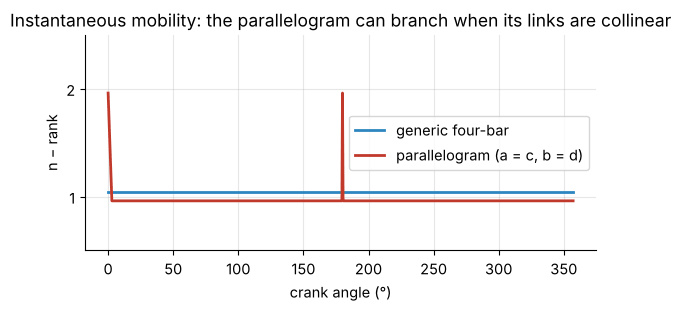

In [6]:
# (2) overconstrained mechanisms: Grübler says 0 (coupling rods) and -2 (Bennett), the rank test says 1.
Lc, qc = mech.coupling_rod_linkage(r=0.5, L=1.0, phi=0.6)
print(f"coupling rods: Grübler = {Lc.grubler()}, numerical mobility n - rank = {Lc.mobility(qc)[0]}   (coordinates {Lc.n_coords}, equations {len(Lc.residual(qc))}, rank {Lc.n_coords - Lc.mobility(qc)[0]})")
params = mech.bennett_parameters()
a_, b_, al, be = params
k = np.sin((be + al) / 2) / np.sin((be - al) / 2)
t1 = 0.8; t2 = 2 * np.arctan(k / np.tan(t1 / 2)); thB = np.array([t1, t2, -t1, -t2])
print(f"Bennett linkage (a={a_:.2f}, b={b_:.3f}, alpha={np.degrees(al):.0f}°, beta={np.degrees(be):.0f}°): closure residual {np.abs(mech.bennett_residual(thB, params)).max():.1e},",
      f"Grübler = {mech.grubler_spatial(4, [1] * 4)}, numerical mobility = {mech.numerical_mobility(lambda t: mech.bennett_residual(t, params), thB)[0]}")
print("spatial formula applied to the planar four-bar:", mech.grubler_spatial(4, [1] * 4), "(wrong m)  vs planar:", mech.grubler_planar(4, [1] * 4))
# the same Bennett closure holds along a whole family: sweep theta_1
res = [np.abs(mech.bennett_residual([t, 2 * np.arctan(k / np.tan(t / 2)), -t, -2 * np.arctan(k / np.tan(t / 2))], params)).max() for t in np.linspace(0.3, 2.8, 30)]
print("Bennett closure residual along the family theta_1 in [0.3, 2.8]:", f"{max(res):.1e}")
assert Lc.grubler() == 0 and Lc.mobility(qc)[0] == 1 and max(res) < 1e-9

# (4) special configurations: mobility along a full crank turn
gen, par = mech.fourbar_linkage(1.0, 2.5, 2.0, 2.2, 0.7), None
ths = np.linspace(0.05, 2 * np.pi - 0.05, 400); ths = np.sort(np.concatenate([ths, [0.0, np.pi]]))
mob_gen, mob_par = [], []
for t in ths:
    Lg, qg = mech.fourbar_linkage(1.0, 2.5, 2.0, 2.2, t); mob_gen.append(Lg.mobility(qg)[0])
    Lp, qp = mech.fourbar_linkage(1.0, 2.0, 1.0, 2.0, t); mob_par.append(Lp.mobility(qp)[0])
mob_gen, mob_par = np.array(mob_gen), np.array(mob_par)
print("generic four-bar: mobility values seen:", sorted(set(mob_gen)), "| parallelogram: values seen", sorted(set(mob_par)),
      "at crank angles (deg):", np.degrees(ths[mob_par == 2]).round(1))
fig, ax = plt.subplots(figsize=(6.6, 2.8))
ax.plot(np.degrees(ths), mob_gen + 0.04, "-", color="#2e86c1", lw=2, label="generic four-bar"); ax.plot(np.degrees(ths), mob_par - 0.04, "-", color="#c0392b", lw=2, label="parallelogram (a = c, b = d)")
ax.set_xlabel("crank angle (°)"); ax.set_ylabel("n − rank"); ax.set_yticks([1, 2]); ax.set_ylim(0.5, 2.5); ax.legend(loc="center right")
ax.set_title("Instantaneous mobility: the parallelogram can branch when its links are collinear"); plt.show()

The rank test (1.5) resolves the paradoxes that (1.4) cannot: the coupling rods have 12 coordinates and 12 equations but only rank 11, because the
loops are geometrically dependent; the Bennett linkage has a one-parameter family of closures although the count is negative; the
parallelogram has mobility 1 almost everywhere and 2 at the two collinear configurations, where the rank drops.

> **Practical rule.** Use (1.4) to *predict*, and (1.5) — or a simulator — to *confirm*, whenever a mechanism has symmetry, parallel links, or axes
> that meet; never accept a negative or zero count for a mechanism that obviously moves.

## 7. Worked examples

**Example 1.3.1 (the four-bar).** $N=4$, $J=4$ revolute joints, $m=3$: $\text{DOF}=3(4-1-4)+4=1$. Check: the rank of the 8 loop-closure equations in 9 body coordinates is 8
(code of Section 3), so the mobility is $9-8=1$.

**Example 1.3.2 (the slider-crank).** $N=4$; joints R, R, R, P, so $\sum f_i = 4$: $\text{DOF}=3(4-1-4)+4 = 1$. For $r=0.1$ m and $l=0.3$ m the piston is at
$x = 0.1\cos 60^\circ + \sqrt{0.3^2 - 0.1^2\sin^2 60^\circ} = 0.05 + 0.2872 = 0.3372$ m when the crank is at $60^\circ$.

**Example 1.3.3 (the Stewart platform).** $N=14$; six U ($f=2$), six P ($f=1$), six S ($f=3$): $6(14-1-18)+36 = 6$. The numerical mobility of (1.5) is 6, and with
all six leg lengths locked it is 0 (a rigid hexapod).

**Example 1.3.4 (a closed arm).** A UR5e (6R) with its tool welded to a fixed workpiece: $N=7$, $J=6+1$, $\sum f_i = 6$: $6(7-1-7)+6=0$. An iiwa (7R) in the same
situation: $6(8-1-8)+7=1$. Both are confirmed in MuJoCo (Section 5).

**Example 1.3.5 (a humanoid in double support).** $N=14$, $J=14$, $\sum f_i = 12$: $6(14-1-14)+12=6$ DOF in the lower body; with the 8 joints of the arms and
head the whole OP3 has 14 DOF — confirmed in MuJoCo.

**Example 1.3.6 (the Delta robot).** $N=11$ (ground, platform, 3 upper arms, 6 rods), 3 R + 12 S: $6(11-1-15) + 3 + 36 = 9$. Six of those are the free spins of the rods about
their own axes, so the useful mobility is $9 - 6 = 3$.

**Example 1.3.7 (the paradox of the coupling rods).** $N=5$, $J=6$: $3(5-1-6)+6 = 0$, yet the mechanism has 1 DOF (rank test above): the three parallel cranks make two of the loop equations redundant.

In [7]:
# 1.3.1
print("1.3.1  four-bar:", mech.grubler_planar(4, [1] * 4), "|", L4.mobility(q0)[0], "| equations rank:", L4.n_coords - L4.mobility(q0)[0])
assert L4.n_coords - L4.mobility(q0)[0] == 8
# 1.3.2
rr, ll, t60 = 0.1, 0.3, np.radians(60)
x = mech.slider_crank_x(rr, ll, t60); print("1.3.2  slider-crank:", mech.grubler_planar(4, [1] * 4), "| piston x =", round(x, 4), "m"); assert abs(x - 0.3372) < 5e-5
# 1.3.3
print("1.3.3  Stewart:", mech.grubler_spatial(14, [2] * 6 + [1] * 6 + [3] * 6), "| numerical:", dofs[0], "| all legs locked:", dofs[6]); assert mech.grubler_spatial(14, [2] * 6 + [1] * 6 + [3] * 6) == 6
# 1.3.4
print("1.3.4  welded arms (Grübler):", mech.grubler_spatial(7, [1] * 6 + [0]), mech.grubler_spatial(8, [1] * 7 + [0]), "| MuJoCo:", jc.model_mobility(mu, du), jc.model_mobility(mi, di))
assert (mech.grubler_spatial(7, [1] * 6 + [0]), mech.grubler_spatial(8, [1] * 7 + [0])) == (0, 1)
# 1.3.5
g5 = mech.grubler_spatial(14, [1] * 12 + [0, 0]); print("1.3.5  double support:", g5, "+ 8 =", g5 + 8, "| MuJoCo:", jc.model_mobility(mo, do)); assert g5 + 8 == 14 == jc.model_mobility(mo, do)
# 1.3.6
g6 = mech.grubler_spatial(11, [1] * 3 + [3] * 12); print("1.3.6  Delta: Grübler =", g6, "-> useful mobility", g6 - 6); assert (g6, g6 - 6) == (9, 3)
# 1.3.7
print("1.3.7  coupling rods: Grübler", Lc.grubler(), "numerical", Lc.mobility(qc)[0])

1.3.1  four-bar: 1 | 1 | equations rank: 8
1.3.2  slider-crank: 1 | piston x = 0.3372 m
1.3.3  Stewart: 6 | numerical: 6 | all legs locked: 0
1.3.4  welded arms (Grübler): 0 1 | MuJoCo: 0 1
1.3.5  double support: 6 + 8 = 14 | MuJoCo: 14
1.3.6  Delta: Grübler = 9 -> useful mobility 3
1.3.7  coupling rods: Grübler 0 numerical 1


## 8. Summary

| Idea | Result |
|:--|:--|
| Rigid body | 3 DOF in the plane, 6 DOF in space (counting three points) |
| Joint | freedom $f$, removes $c = m - f$ freedoms ($m=3$ or $6$) |
| Grübler–Kutzbach | $\text{DOF} = m(N-1-J) + \sum f_i$; $N$ counts the ground; equivalently $\sum f_i - mL$ |
| Serial chain | $N = n+1$, $J = n$: DOF $= \sum f_i$ = number of joints (for 1-freedom joints) |
| Four-bar, slider-crank | 1 DOF each (planar); a single motor drives the loop |
| Stewart platform | 6 DOF; $k$ locked legs leave $6 - k$ |
| Exact count | $n - \operatorname{rank}(\partial\Phi/\partial q)$ — also what a simulator computes |
| Failures | wrong $m$; redundant constraints (coupling rods, Bennett); passive freedoms (Delta rods); bifurcations |

### Common mistakes

* Leaving the **ground out of $N$** (the single most common error), or counting it as a moving link.
* Using $m = 6$ for a planar mechanism (or the converse).
* Counting a **spherical** joint as $f = 1$, a **universal** joint as $f=3$, or a **cylindrical** joint as $f=1$.
* Trusting a negative or zero Grübler count for a mechanism that visibly moves: look for parallel links or intersecting axes.
* Forgetting passive freedoms (rotation of a rod about its own axis) when counting *useful* DOF.
* Treating DOF as the number of **actuators**: the DOF is a property of the mechanism, the actuator count of the design (a robot may be under-actuated or, with loops, over-actuated).

## Exercises

**1.3.1** Find the DOF of a planar six-bar (Watt) linkage with 6 links and 7 revolute joints, and of a planar eight-bar with 8 links and 10 revolute joints.

<details><summary>Answer</summary>

Watt: $3(6-1-7)+7 = 1$. Eight-bar: $3(8-1-10)+10 = 1$.
</details>

**1.3.2** A *scissor pair* consists of two bars hinged at their midpoints. The lower end of bar 1 is pinned to the ground, the lower end of bar 2 is
pinned to a slider that moves along the ground. Count its DOF.

<details><summary>Answer</summary>

Links: ground, bar 1, bar 2, slider ($N=4$). Joints: ground–bar 1 (R), bar 1–bar 2 at the midpoints (R), bar 2–slider (R), slider–ground (P): $J=4$, $\sum f_i = 4$.
$3(4-1-4)+4 = 1$. (A scissor *lift* repeats this pair $k$ times; each extra pair adds 2 links and 3 joints, leaving the DOF at 1.)
</details>

**1.3.3** A cube resting on a table. How many DOF? If it is a point mass? If it can only slide (not rotate)?

<details><summary>Answer</summary>

On the table, the cube is a rigid body in the plane: 3 DOF (2 translations, 1 rotation about the vertical); with the table's planar pair, $f=3$ as in Notebook 1.1.
A point mass on a table: 2 DOF. Sliding without rotation: 2 DOF.
</details>

**1.3.4** Compute the DOF of a SCARA arm (RRPR) and of a 6R arm holding a rigid load with a gripper that is a one-freedom prismatic jaw pair (two jaws, each one prismatic joint).

<details><summary>Answer</summary>

SCARA: $6(5-1-4)+4 = 4$. 6R arm plus 2 jaws: $N = 1 + 6 + 2 = 9$, $J = 8$, $\sum f_i = 8$: $6(9-1-8)+8 = 8$ DOF in total (6 arm + 2 jaw positions; the grip only needs one).
</details>

**1.3.5** Show that the Delta robot's useful mobility is 3 and explain which freedoms are passive.

<details><summary>Answer</summary>

Grübler: $6(11-1-15)+3+36 = 9$; six rods each spin about their own axis (passive), so $9-6=3$.
</details>

**1.3.6** (*programming*) For the four-bar of Section 3 ($a=1$, $b=2.5$, $c=2$, $d=2.2$), use `mech.fourbar_closure` over a full crank turn and report the
smallest and largest rocker angle (on the branch used in Section 3), and whether every crank angle can be assembled.

<details><summary>Answer</summary>

The linkage is a crank-rocker: every crank angle can be assembled, and the rocker oscillates between two toggle positions. The numbers are printed
by the check cell below (rocker swing about 71°).
</details>

**1.3.7** (*MuJoCo*) Weld the **Panda's** hand to the world and compute the mobility with the model. Compare with Grübler.

<details><summary>Answer</summary>

Mobility 2: the seven arm joints with six weld constraints leave 1 DOF (the self-motion), and the two coupled finger joints contribute 1 more (the opening of the gripper), which the weld does not touch. The cell below prints the number.
</details>

In [8]:
# --- verification of the exercise answers ---
print("1.3.1", mech.grubler_planar(6, [1] * 7), mech.grubler_planar(8, [1] * 10)); assert (mech.grubler_planar(6, [1] * 7), mech.grubler_planar(8, [1] * 10)) == (1, 1)
print("1.3.2", mech.grubler_planar(4, [1] * 4))
print("1.3.4 SCARA:", mech.grubler_spatial(5, [1] * 4), "| arm + 2 jaws:", mech.grubler_spatial(9, [1] * 8)); assert mech.grubler_spatial(5, [1] * 4) == 4 and mech.grubler_spatial(9, [1] * 8) == 8
print("1.3.5", mech.grubler_spatial(11, [1] * 3 + [3] * 12) - 6)
th4 = np.array([mech.fourbar_closure(1.0, 2.5, 2.0, 2.2, t)[1] for t in np.linspace(0, 2 * np.pi, 721)])
th4 = np.unwrap(th4)
print(f"1.3.6 rocker angle ranges from {np.degrees(th4.min()):.1f}° to {np.degrees(th4.max()):.1f}° (swing {np.degrees(np.ptp(th4)):.1f}°); all 721 crank angles assemble:", not np.isnan(th4).any())
mp, dp = welded("panda", ["hand"]); dp.qpos[:] = random_pose(mp); mujoco.mj_forward(mp, dp)
print("1.3.7 Panda hand welded: nv =", mp.nv, ", rank =", jc.equality_rank(mp, dp), ", mobility =", jc.model_mobility(mp, dp))

1.3.1 1 1
1.3.2 1
1.3.4 SCARA: 4 | arm + 2 jaws: 8
1.3.5 3
1.3.6 rocker angle ranges from 67.2° to 138.5° (swing 71.3°); all 721 crank angles assemble: True


1.3.7 Panda hand welded: nv = 9 , rank = 7 , mobility = 2


## Further reading and lectures

* Craig, Ch. 1 and §3.1 (links and joints); Lynch & Park, §2.1–2.2, which contains the same derivation and a table of joint constraints for planar and spatial bodies; Spong et al., Ch. 1.
* Video: [Modern Robotics — 2.1 DOF of a rigid body](https://www.youtube.com/watch?v=z29hYlagOYM); [Modern Robotics — 2.2 DOF of a robot (Grübler)](https://www.youtube.com/watch?v=zI64DyaRUvQ); [Prof. G. C. Nandi — Lecture 2 — A simple two-link manipulator](https://www.youtube.com/watch?v=4eAlCjFMq2Q).
* Bennett's linkage and other overconstrained mechanisms are treated in textbooks on mechanism theory; the numerical rank test used here is a standard way to detect them.
* Next: Notebook 1.4 asks what *shape* the set of all configurations has — the configuration space.

---

[← 1.2 A Tour of Real Robots](1.2-a-tour-of-real-robots.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md) &nbsp;·&nbsp; [1.4 Configuration Space →](1.4-configuration-space.ipynb)